In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.DROPOUT_P,
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


opti = [
    # ("SGD", 0.001),
    # ("SGD", 0.01),
    ("SGD", 0.1),
    # ("Adam", 0.0001),
    # ("Adam", 0.001),
    # ("Adam", 0.01)
]

batches = [
    # 64,
    100,
    # 256,
    # 512
]

neurons = [
    (64, 32),
    (128, 64),
    (256, 128),
    (512, 256)
]

dropout = [
     0,
    0.1,
    0.2,
     0.5
]

# Best Worst-Class Recall -> SGD-0.1/128-64/B100/D0.2: Shirt (0.7090)   CM deviation 0.273
# Min CM Deviation       -> Adam-0.001/128-64/B512/D0.2: 0.2697 wost class recall 0.695 (shirt)


#i choose SGD-0.1/128-64/B100/D0.2
def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=30,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 12




Optimizador: SGD
Dropout: 0

Iniciando entrenamiento... Opti -> SGD | Drop -> 0 | Batch size -> 100
Training time: 55.81 seconds

Peak GPU memory: 18.00 MB

Test CEL: 0.36641
Test accuracy: 87.66%

----------------- SGD-0.1/64-32/B100/D0 -----------------


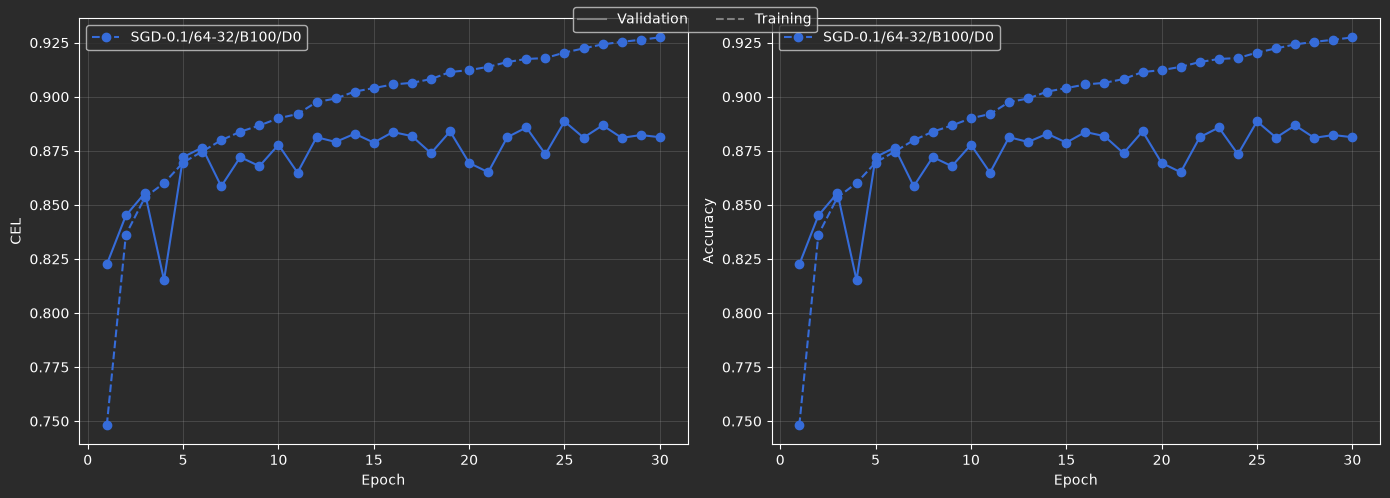

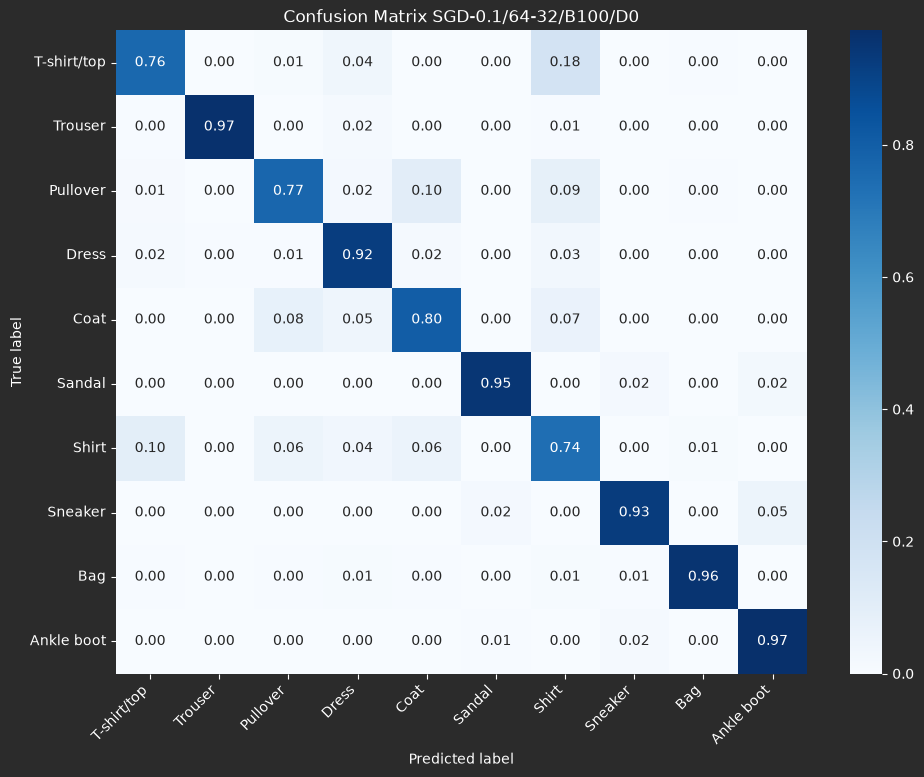


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 58.91 seconds

Peak GPU memory: 18.40 MB

Test CEL: 0.35178
Test accuracy: 87.70%

----------------- SGD-0.1/64-32/B100/D0.2 -----------------


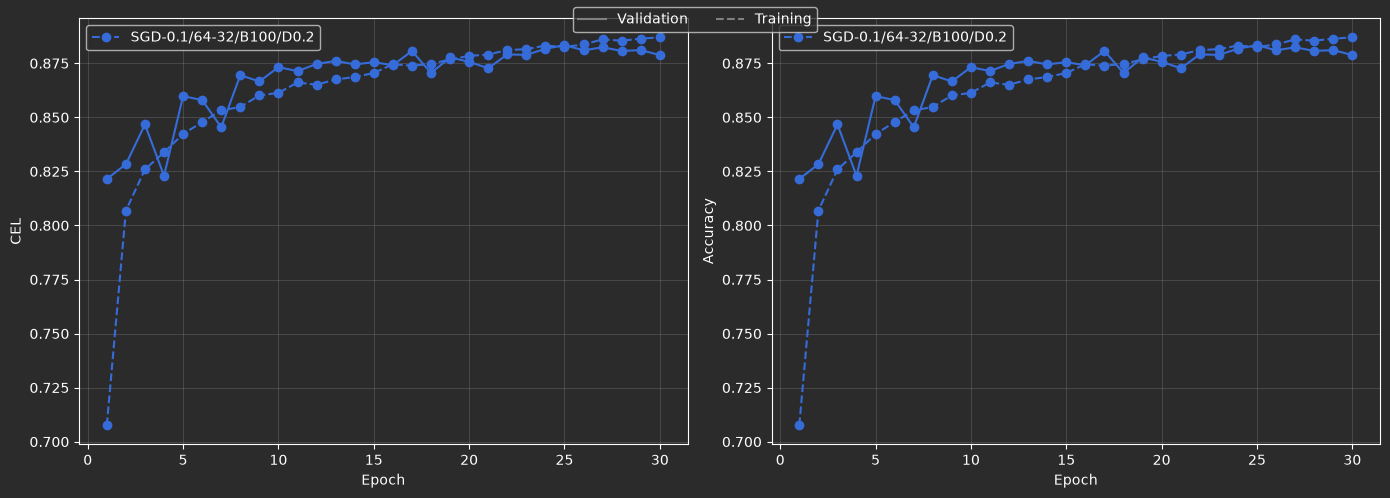

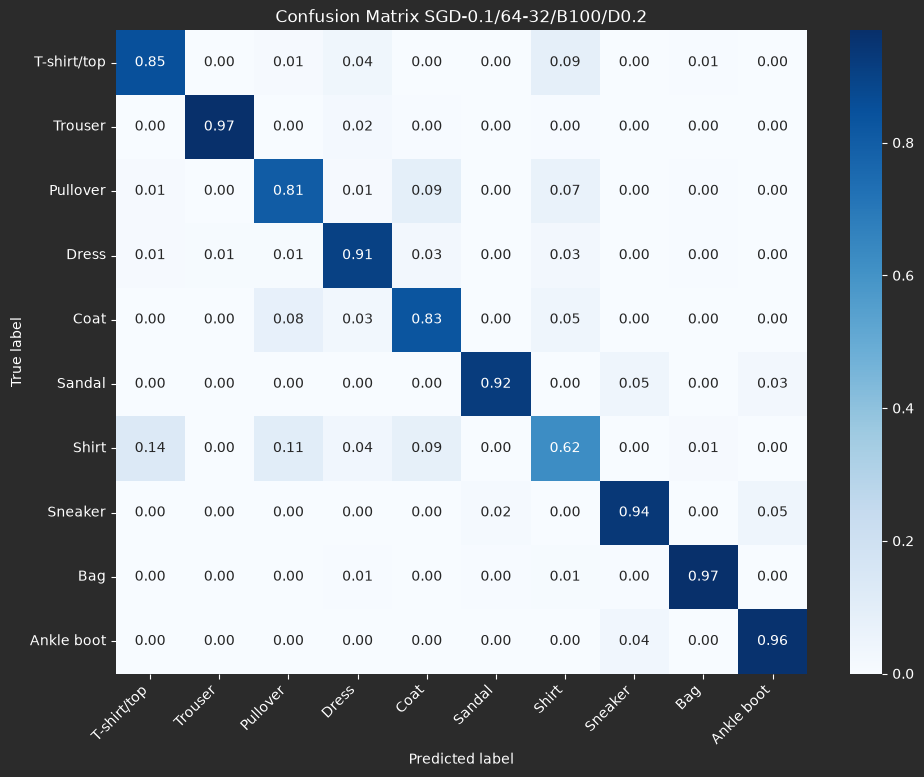


Optimizador: SGD
Dropout: 0.5

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.5 | Batch size -> 100
Training time: 51.72 seconds

Peak GPU memory: 18.81 MB

Test CEL: 0.40958
Test accuracy: 84.95%

----------------- SGD-0.1/64-32/B100/D0.5 -----------------


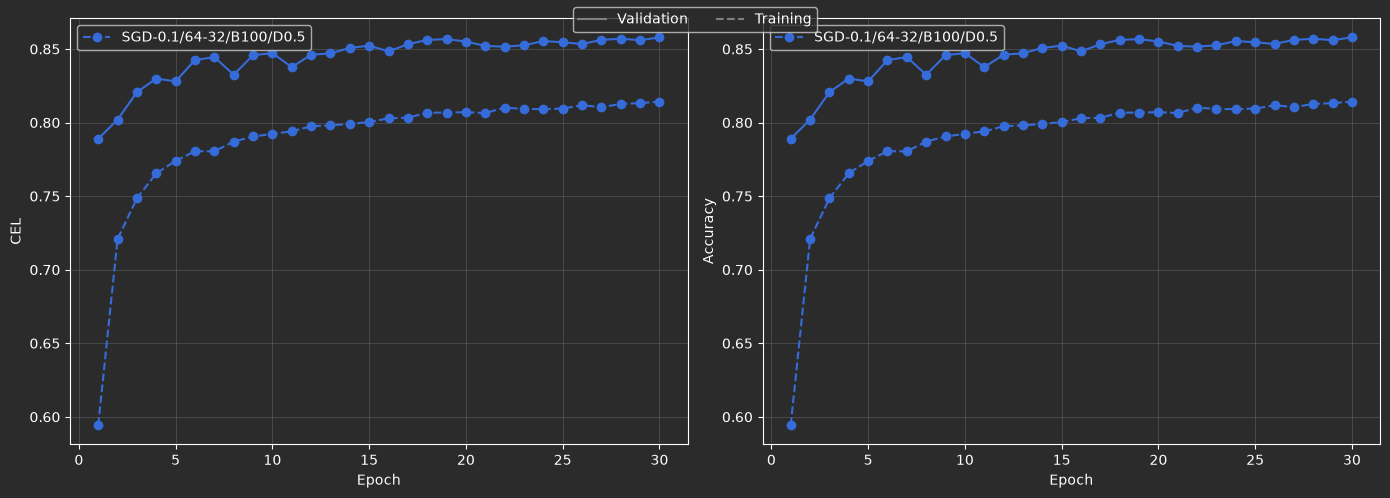

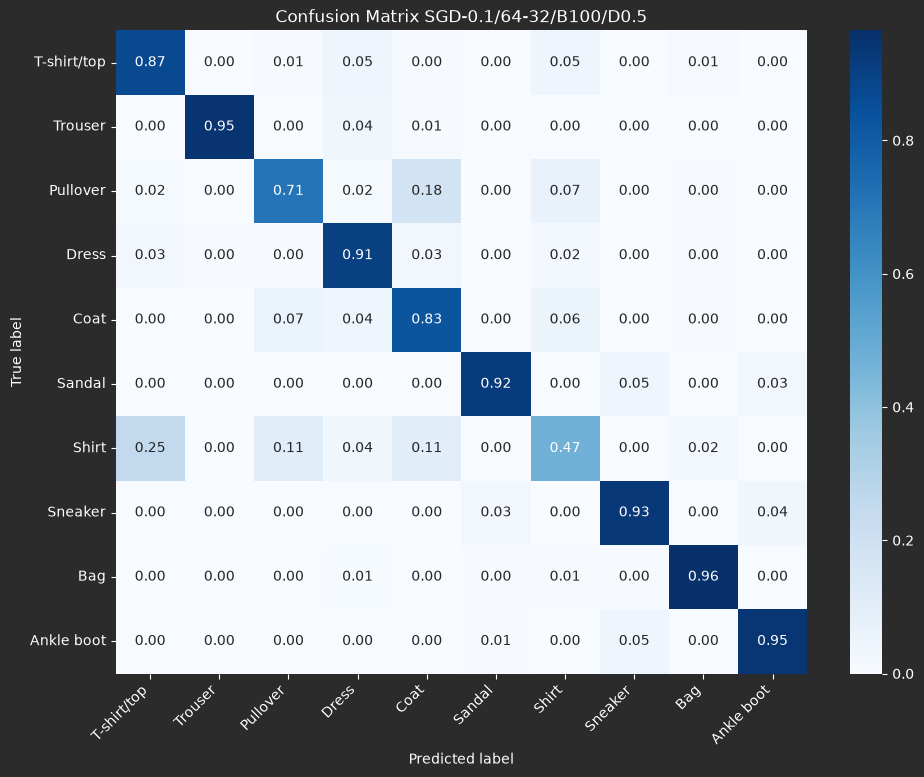


Optimizador: SGD
Dropout: 0

Iniciando entrenamiento... Opti -> SGD | Drop -> 0 | Batch size -> 100
Training time: 124.86 seconds

Peak GPU memory: 19.68 MB

Test CEL: 0.38093
Test accuracy: 87.78%

----------------- SGD-0.1/128-64/B100/D0 -----------------


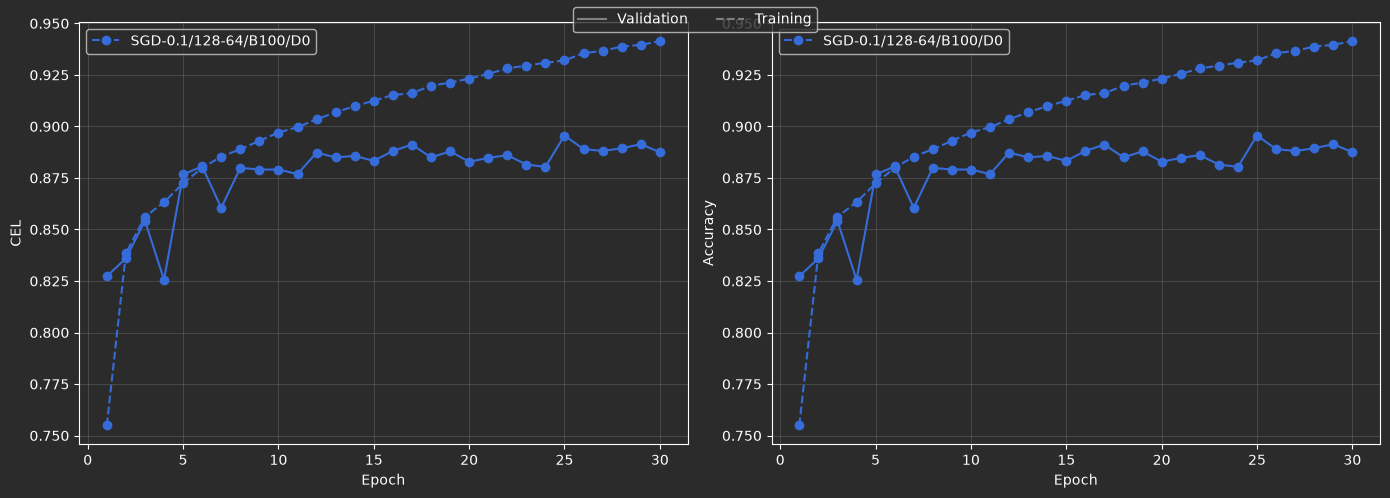

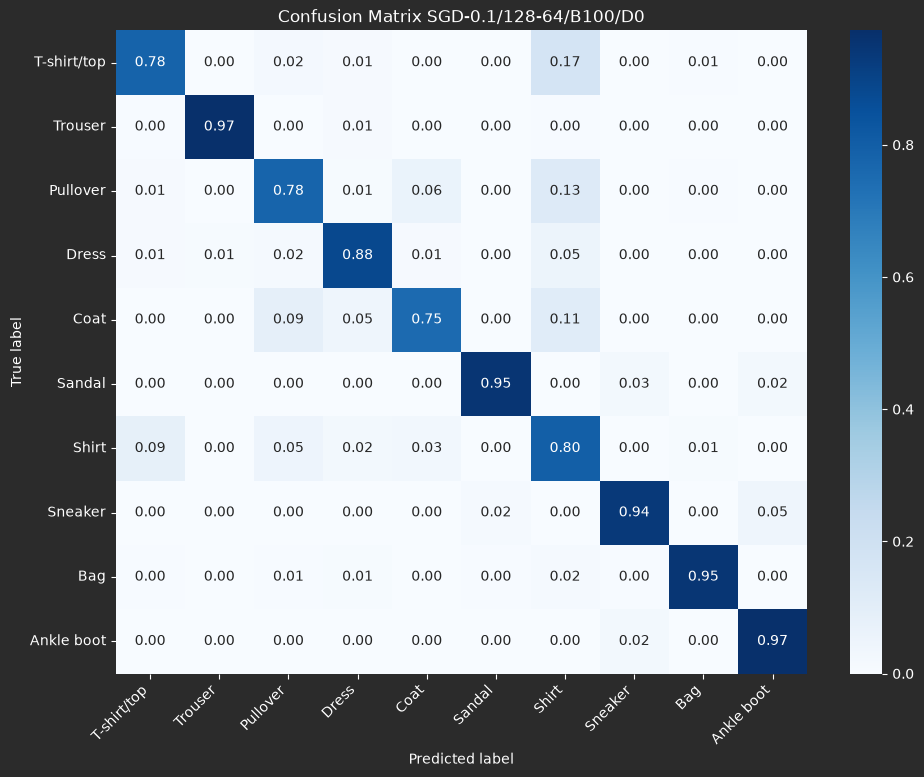


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 84.78 seconds

Peak GPU memory: 20.52 MB

Test CEL: 0.32672
Test accuracy: 88.65%

----------------- SGD-0.1/128-64/B100/D0.2 -----------------


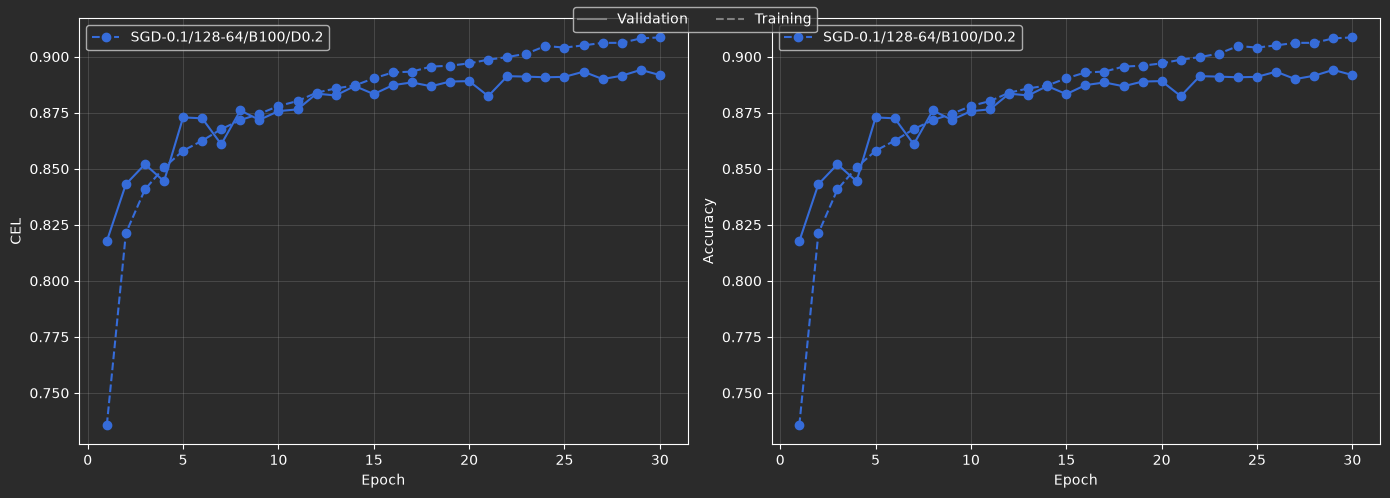

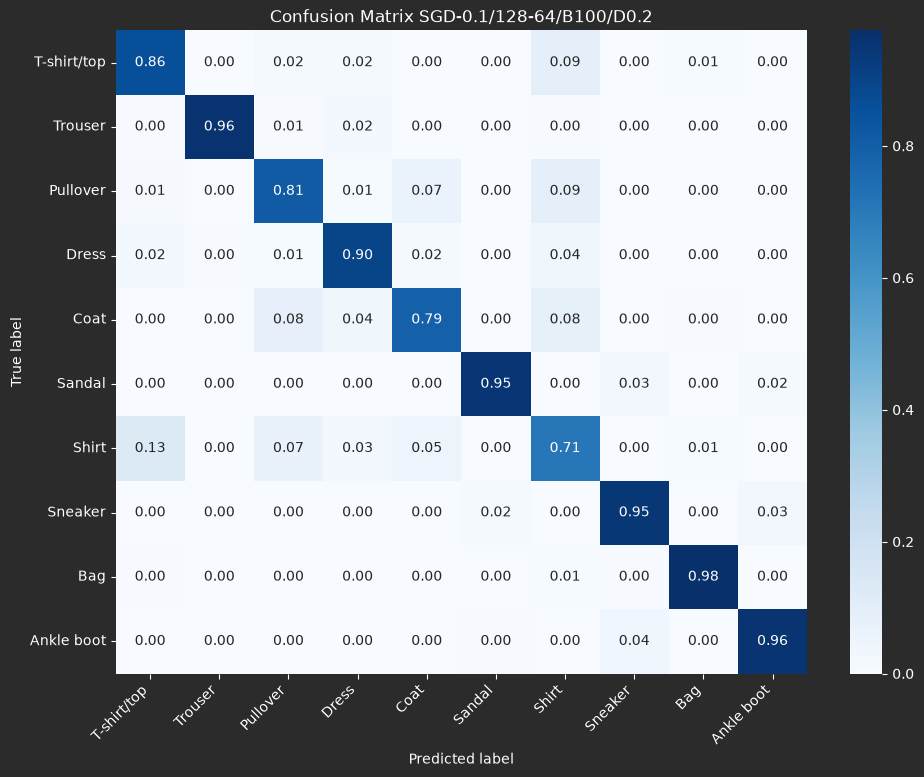


Optimizador: SGD
Dropout: 0.5

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.5 | Batch size -> 100
Training time: 51.87 seconds

Peak GPU memory: 21.35 MB

Test CEL: 0.36784
Test accuracy: 86.99%

----------------- SGD-0.1/128-64/B100/D0.5 -----------------


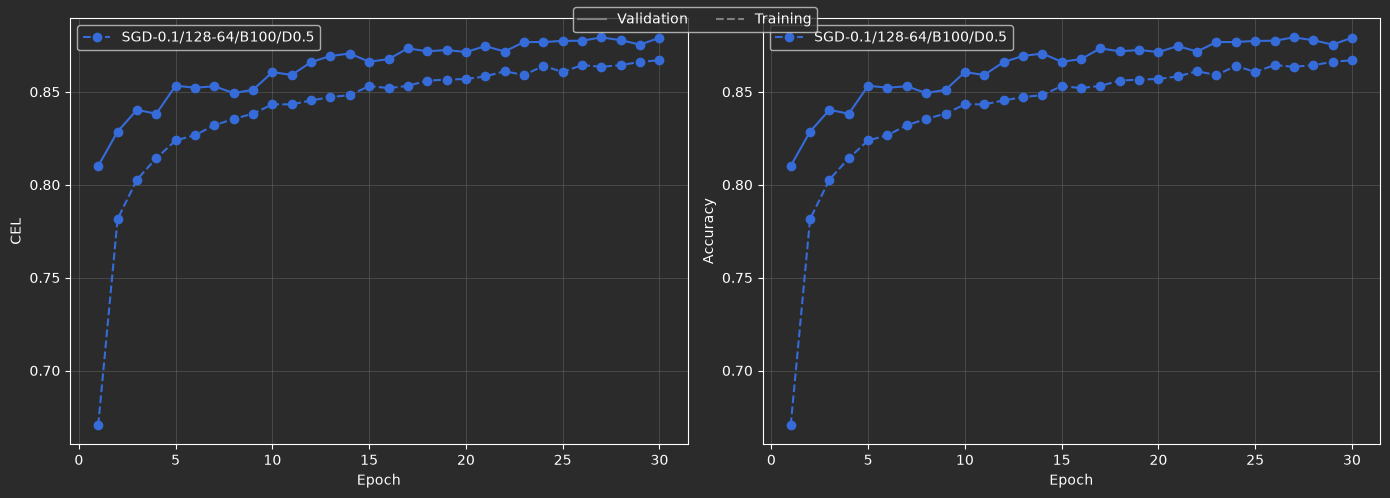

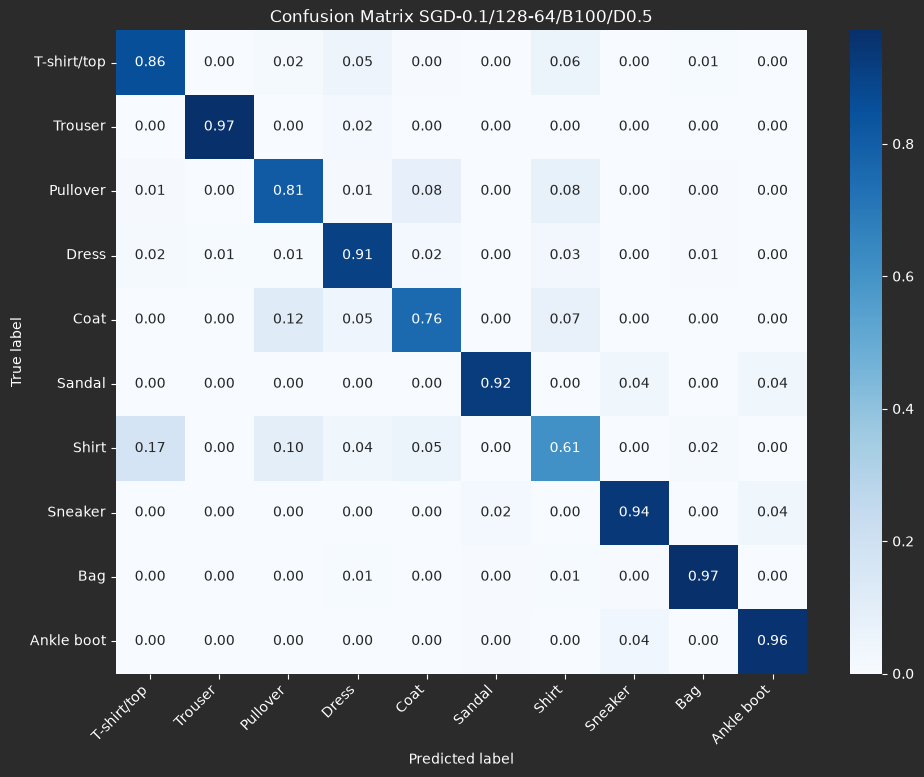


Optimizador: SGD
Dropout: 0

Iniciando entrenamiento... Opti -> SGD | Drop -> 0 | Batch size -> 100
Training time: 52.80 seconds

Peak GPU memory: 23.22 MB

Test CEL: 0.36625
Test accuracy: 88.34%

----------------- SGD-0.1/256-128/B100/D0 -----------------


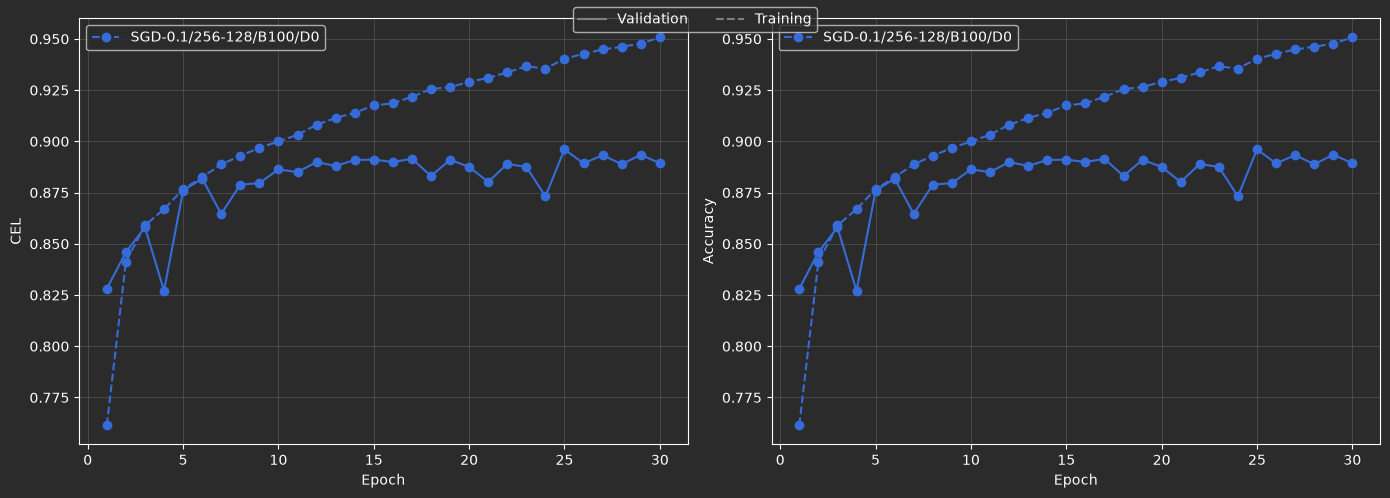

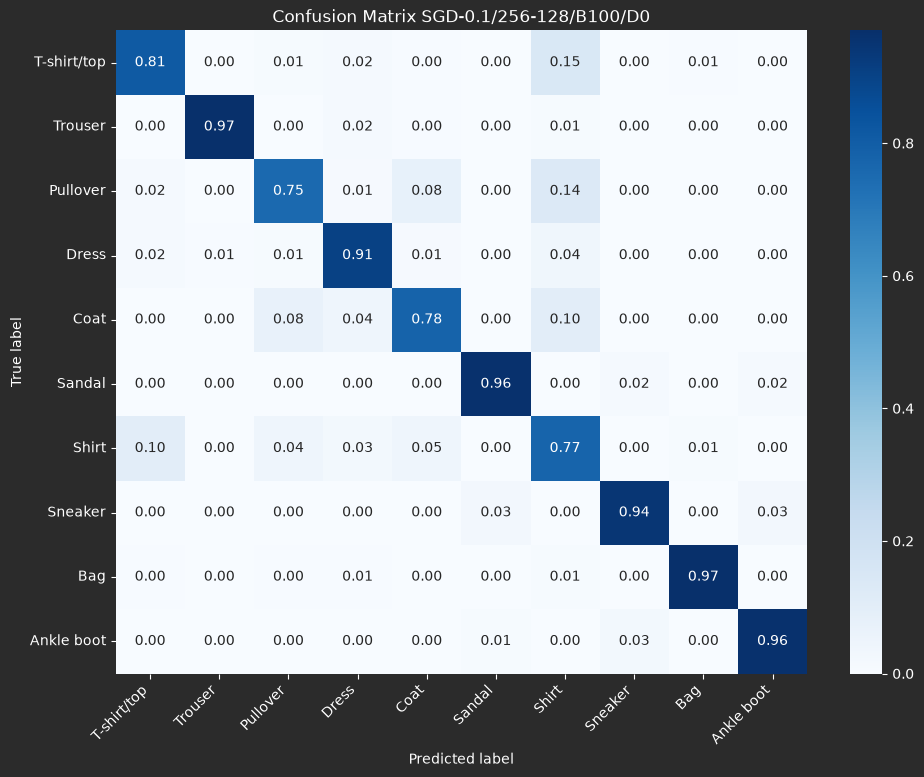


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 60.52 seconds

Peak GPU memory: 25.02 MB

Test CEL: 0.32642
Test accuracy: 88.72%

----------------- SGD-0.1/256-128/B100/D0.2 -----------------


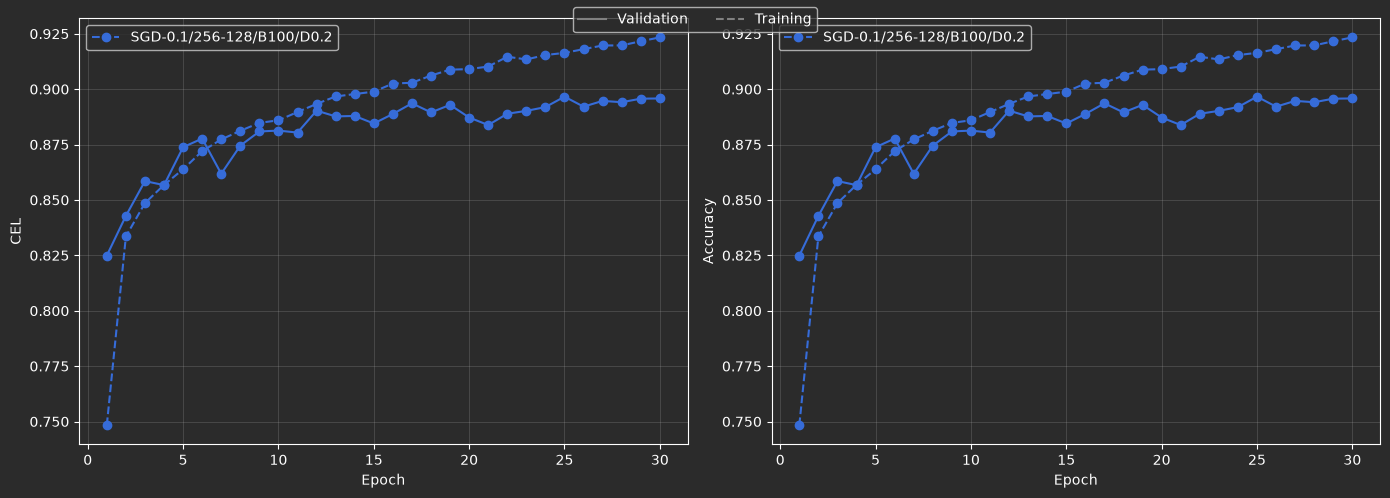

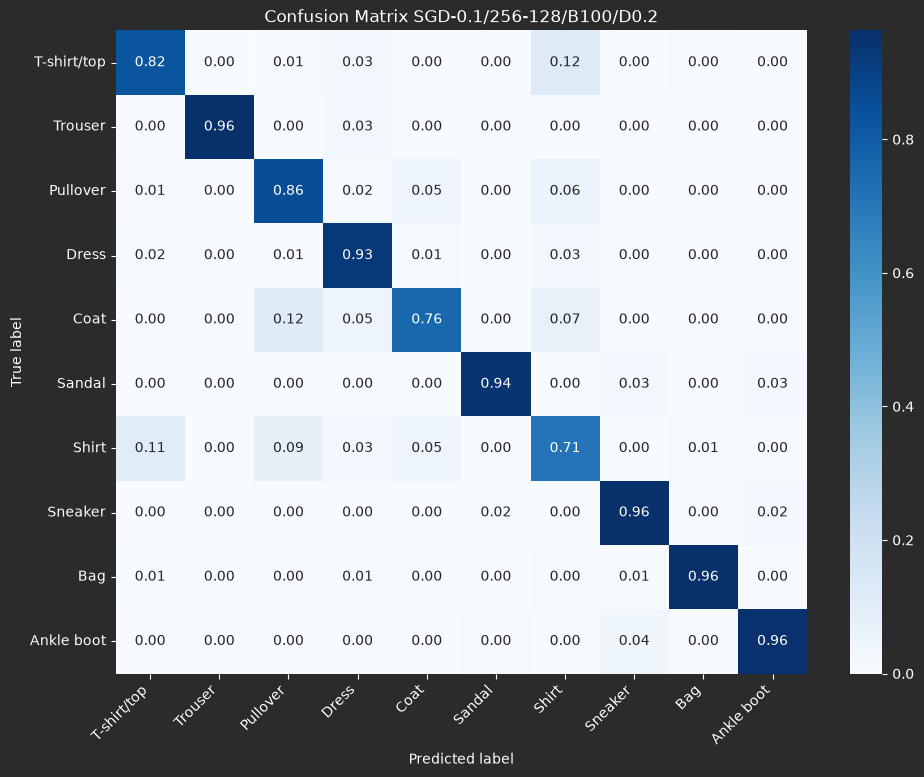


Optimizador: SGD
Dropout: 0.5

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.5 | Batch size -> 100
Training time: 54.04 seconds

Peak GPU memory: 26.81 MB

Test CEL: 0.33688
Test accuracy: 88.07%

----------------- SGD-0.1/256-128/B100/D0.5 -----------------


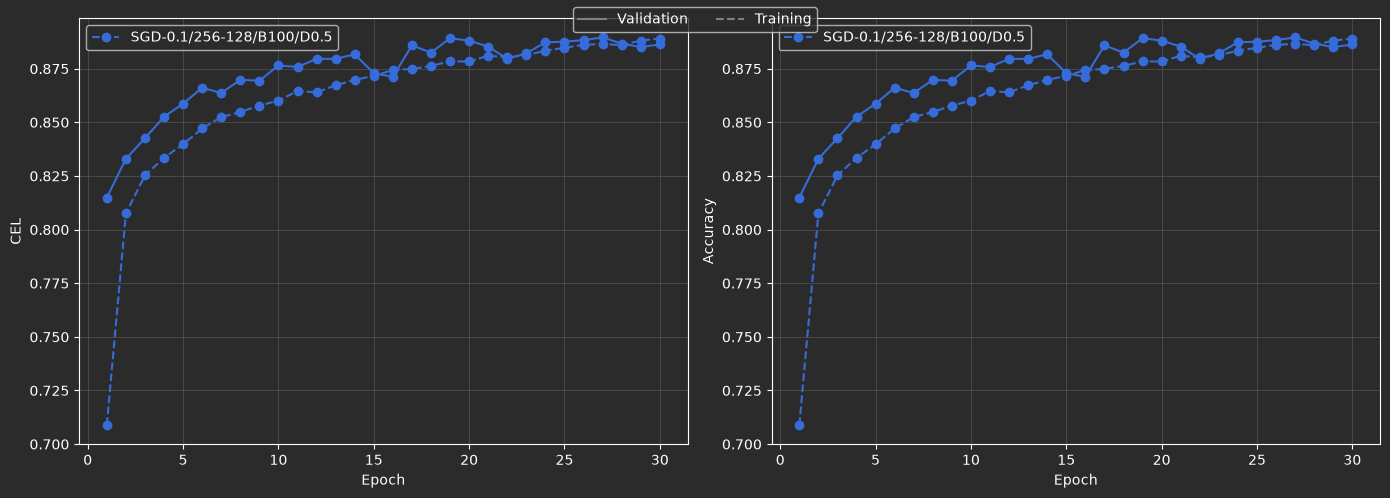

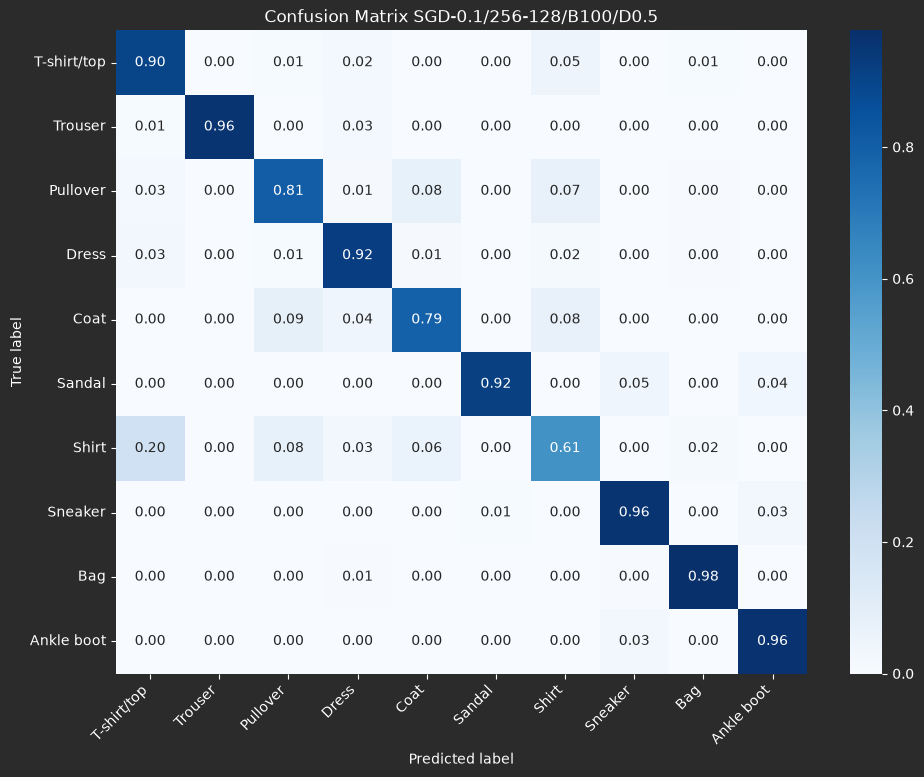


Optimizador: SGD
Dropout: 0

Iniciando entrenamiento... Opti -> SGD | Drop -> 0 | Batch size -> 100
Training time: 51.71 seconds

Peak GPU memory: 31.73 MB

Test CEL: 0.38906
Test accuracy: 88.12%

----------------- SGD-0.1/512-256/B100/D0 -----------------


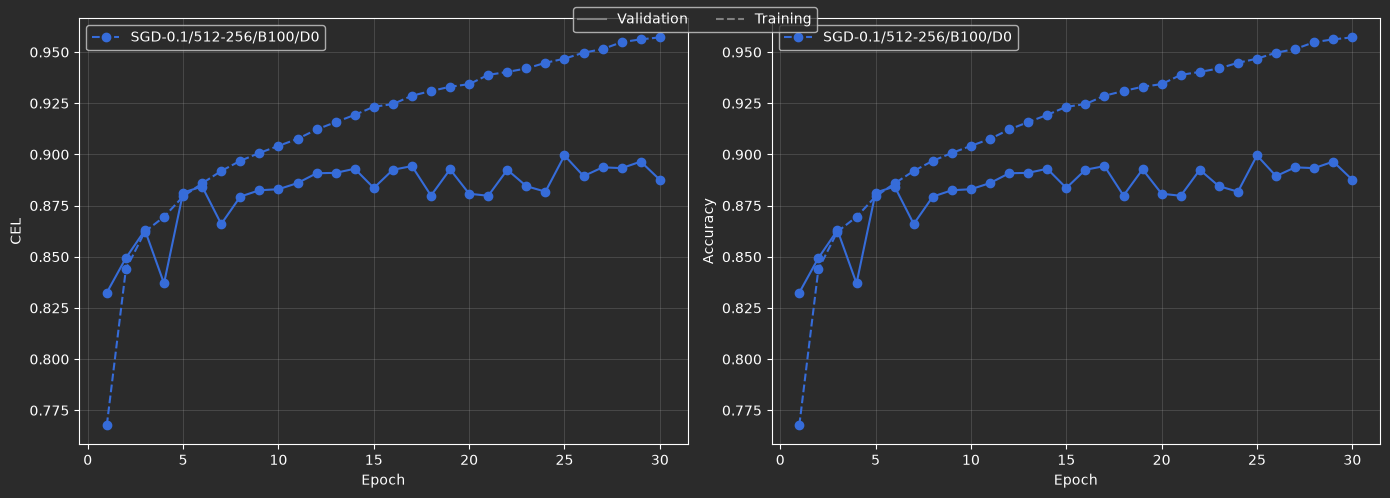

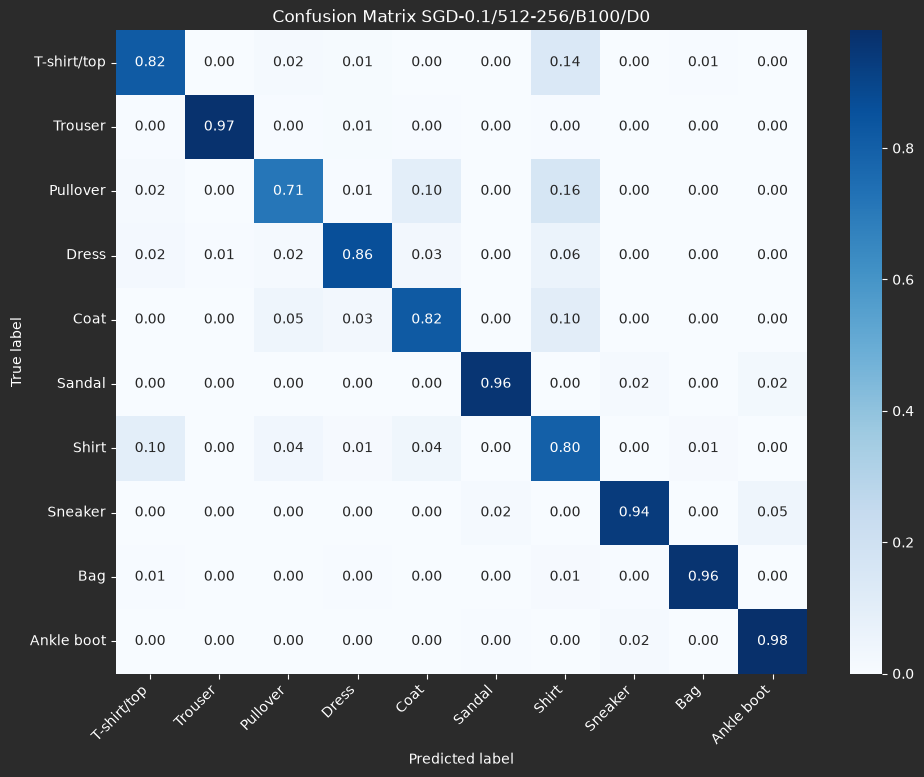


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 50.31 seconds

Peak GPU memory: 35.82 MB

Test CEL: 0.31832
Test accuracy: 88.68%

----------------- SGD-0.1/512-256/B100/D0.2 -----------------


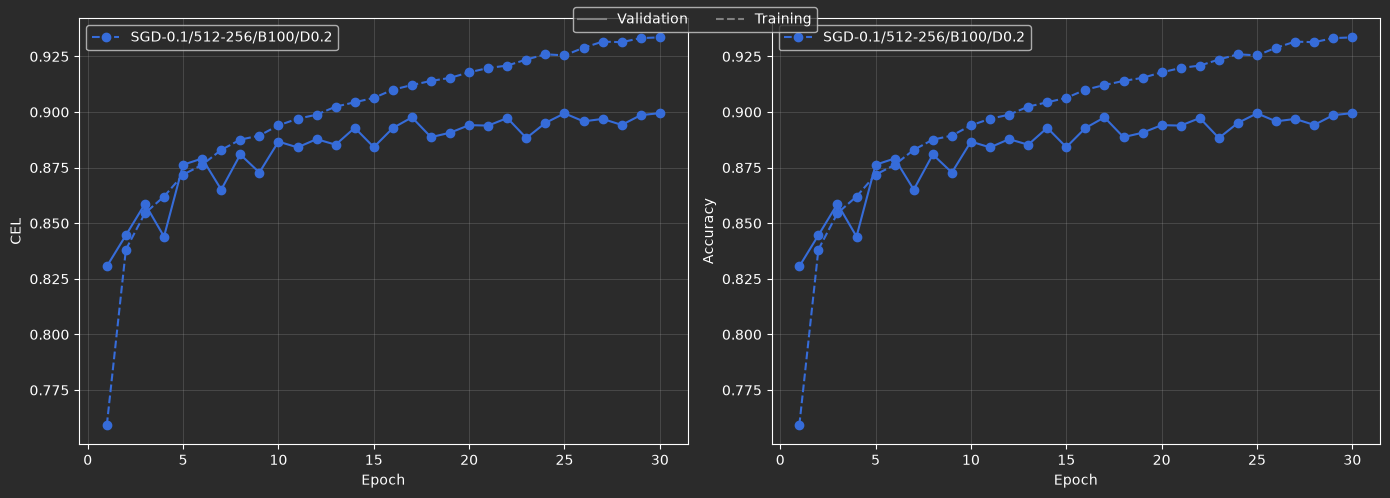

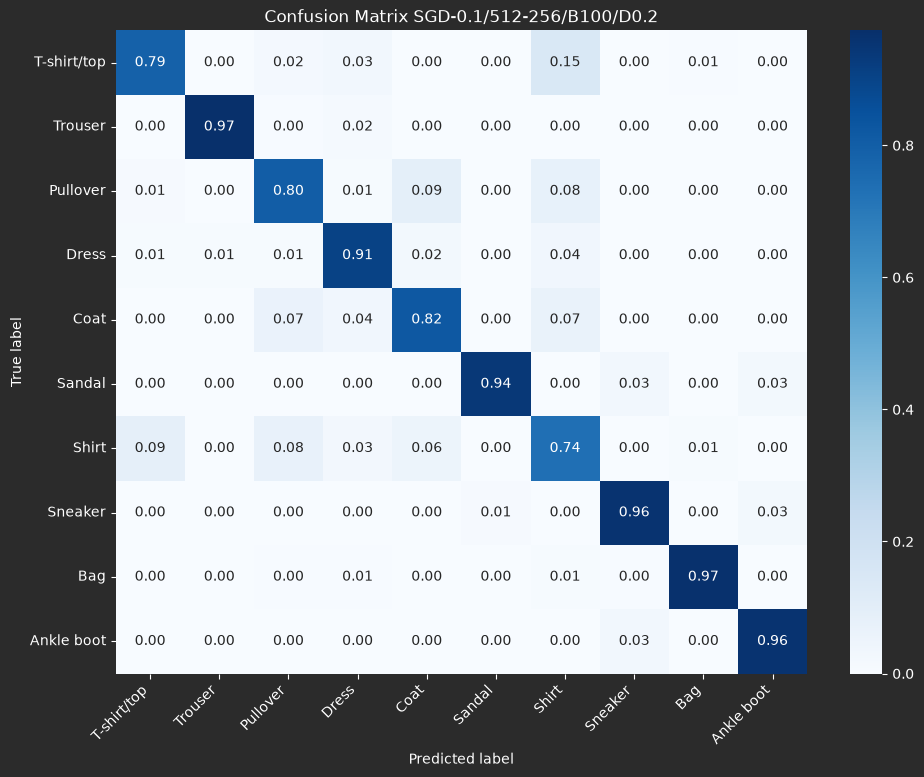


Optimizador: SGD
Dropout: 0.5

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.5 | Batch size -> 100
Training time: 50.03 seconds

Peak GPU memory: 39.91 MB

Test CEL: 0.32250
Test accuracy: 88.60%

----------------- SGD-0.1/512-256/B100/D0.5 -----------------


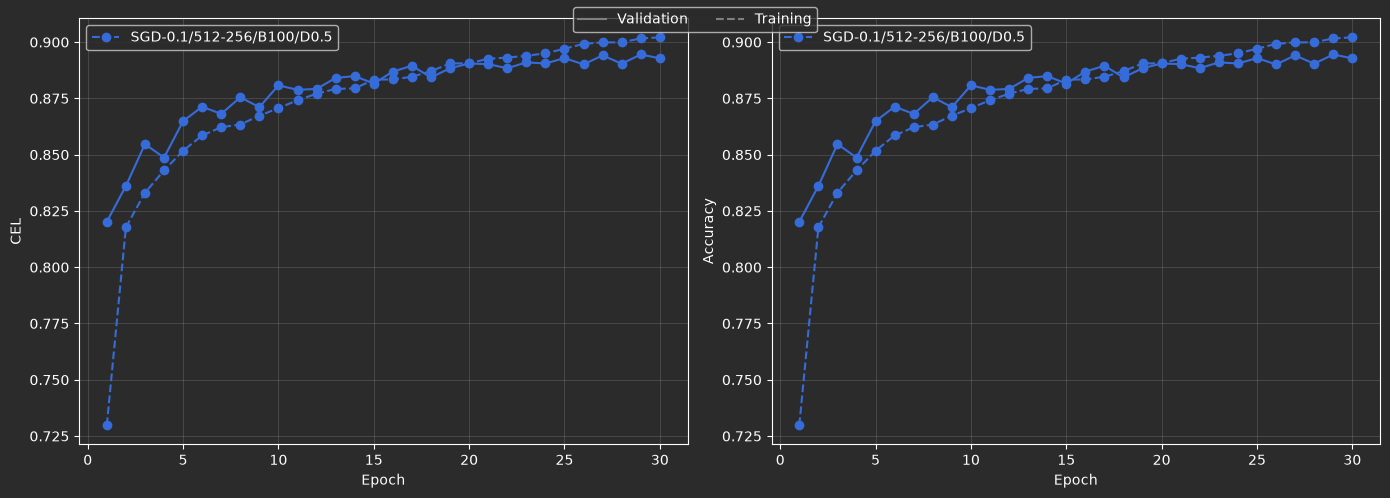

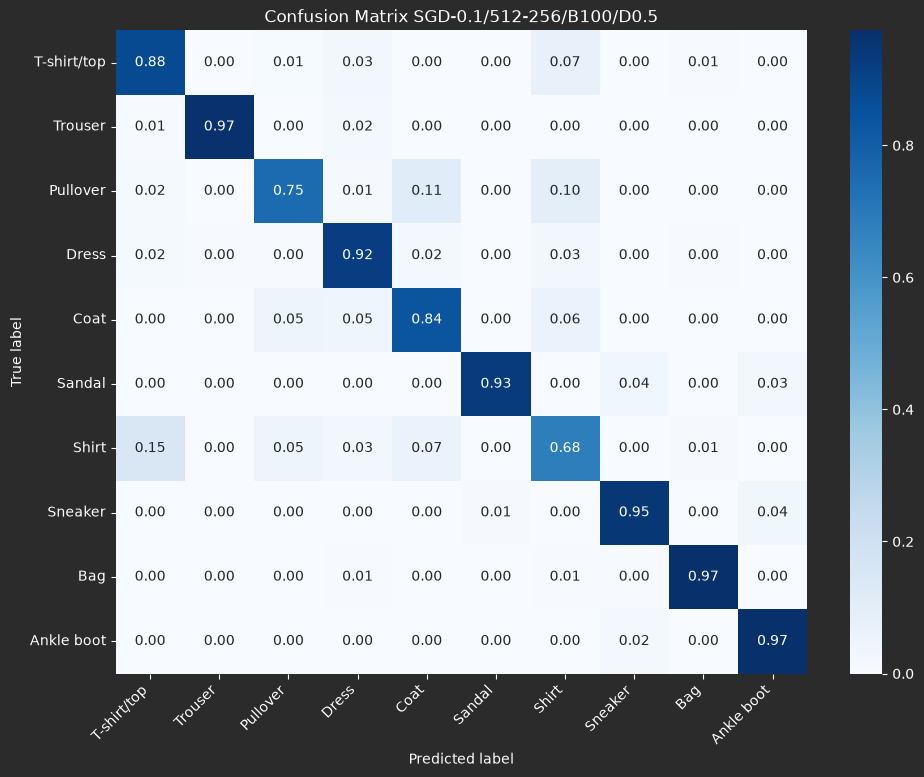

In [2]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: (0,):-----------------------------------

----------------- SGD-0.1/64-32/B100/D0 -----------------
----------------- SGD-0.1/128-64/B100/D0 -----------------
----------------- SGD-0.1/256-128/B100/D0 -----------------
----------------- SGD-0.1/512-256/B100/D0 -----------------


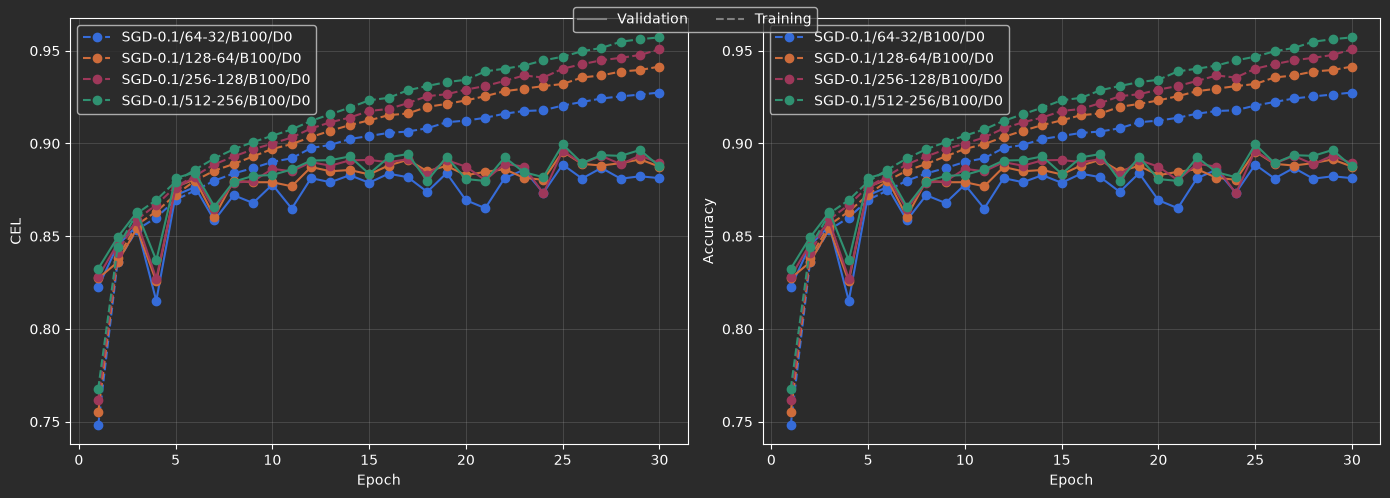

                        Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.1/64-32/B100/D0        0.192      0.346      0.927      0.881     0.877       Shirt              0.738  0.046        0.326        55.811
SGD-0.1/128-64/B100/D0       0.158      0.343      0.941      0.887     0.878        Coat              0.755  0.054        0.317       124.862
SGD-0.1/256-128/B100/D0      0.135      0.337      0.951      0.889     0.883    Pullover              0.755  0.061        0.298        52.802
SGD-0.1/512-256/B100/D0      0.115      0.352      0.957      0.888     0.881    Pullover              0.713  0.070        0.312        51.709

--- Best experiments ---
Max Test Accu      -> SGD-0.1/256-128/B100/D0: 0.8834
Max Valid Accu     -> SGD-0.1/256-128/B100/D0: 0.8893
Best Worst-Class Recall -> SGD-0.1/128-64/B100/D0: Coat (0.7550)
Min CM Deviation       -> SGD-0.1/256-128/B100/D0: 0.2985
Min Training Time       -> S

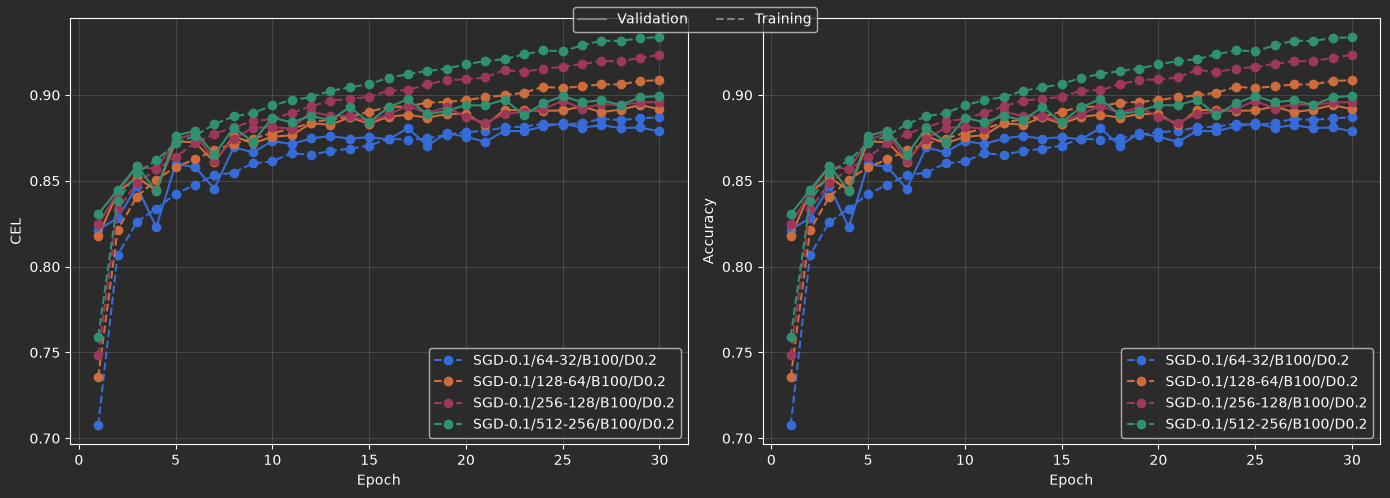

                          Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.1/64-32/B100/D0.2        0.308      0.334      0.887      0.879     0.877       Shirt              0.622  0.008        0.337        58.909
SGD-0.1/128-64/B100/D0.2       0.243      0.304      0.909      0.892     0.887       Shirt              0.709  0.017        0.273        84.777
SGD-0.1/256-128/B100/D0.2      0.205      0.300      0.923      0.896     0.887       Shirt              0.713  0.028        0.279        60.524
SGD-0.1/512-256/B100/D0.2      0.173      0.295      0.934      0.899     0.887       Shirt              0.735  0.034        0.274        50.306

--- Best experiments ---
Max Test Accu      -> SGD-0.1/256-128/B100/D0.2: 0.8872
Max Valid Accu     -> SGD-0.1/512-256/B100/D0.2: 0.8995
Best Worst-Class Recall -> SGD-0.1/512-256/B100/D0.2: Shirt (0.7350)
Min CM Deviation       -> SGD-0.1/128-64/B100/D0.2: 0.2727
Min Train

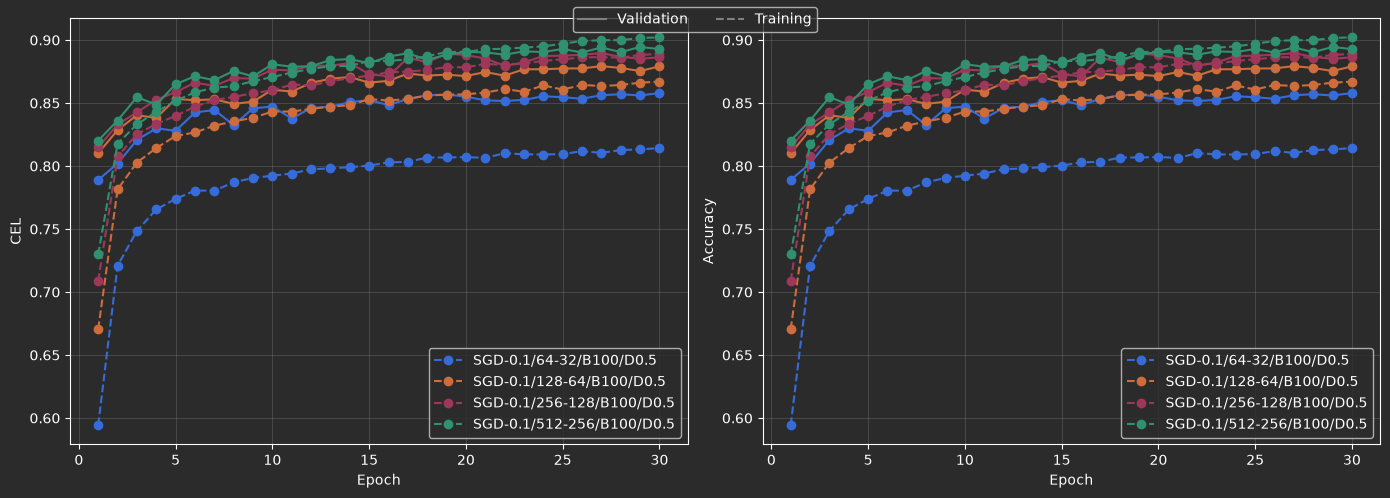

                          Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.1/64-32/B100/D0.5        0.528      0.398      0.814      0.858     0.850       Shirt              0.469 -0.044        0.593        51.715
SGD-0.1/128-64/B100/D0.5       0.375      0.346      0.867      0.879     0.870       Shirt              0.609 -0.012        0.386        51.868
SGD-0.1/256-128/B100/D0.5      0.302      0.316      0.889      0.886     0.881       Shirt              0.609  0.003        0.352        54.040
SGD-0.1/512-256/B100/D0.5      0.261      0.300      0.902      0.893     0.886       Shirt              0.684  0.009        0.296        50.033

--- Best experiments ---
Max Test Accu      -> SGD-0.1/512-256/B100/D0.5: 0.8860
Max Valid Accu     -> SGD-0.1/512-256/B100/D0.5: 0.8928
Best Worst-Class Recall -> SGD-0.1/512-256/B100/D0.5: Shirt (0.6840)
Min CM Deviation       -> SGD-0.1/512-256/B100/D0.5: 0.2958
Min Trai

In [3]:
viewAftermath(aftermath)

import winsound
for _ in range(14):
    winsound.MessageBeep(winsound.MB_ICONEXCLAMATION)
    time.sleep(0.5)